In [ ]:
!pip install torch
!pip install torchtext==0.4.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.9 MB/s eta 0:00:00


#Part 1

In [ ]:
from torchtext import data, datasets
import torch
# For tokenization
TEXT = data.Field(tokenize='spacy',
                  tokenizer_language='en_core_web_sm',
                  include_lengths = True)
# For multi-class classification labels
LABEL = data.LabelField()
# Load the TREC dataset
# train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)
train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)

In [ ]:
TEXT.build_vocab(train_data,
                max_size=25000,
                vectors="glove.6B.100d",
                unk_init=torch.Tensor.normal_)
LABEL.build_vocab(train_data)

In [ ]:
print(f"Number of unique tokens in TEXT vocabulary: {len(TEXT.vocab)}")

Number of unique tokens in TEXT vocabulary: 9330


In [ ]:
oov_words = []
for example in train_data.examples:
    for token in example.text:
        if token not in TEXT.vocab.stoi:
            oov_words.append(token)

unique_oov_words = list(set(oov_words))
print(f"Number of out-of-vocabulary words: {len(unique_oov_words)}")
print(f"First 20 out-of-vocabulary words: {unique_oov_words[:20]}")

Number of out-of-vocabulary words (not in GloVe): 0
First 20 OOV words: []


In [ ]:
oov_counts_by_topic = {}

for example in train_data.examples:
    label = example.label
    tokens = example.text

    if label not in oov_counts_by_topic:
        oov_counts_by_topic[label] = 0

    for token in tokens:
        if token not in TEXT.vocab.stoi:
            oov_counts_by_topic[label] += 1

print("Number of out-of-vocabulary words per topic category:")
for topic, count in oov_counts_by_topic.items():
    print(f"Topic: {topic}, OOV Count: {count}")

Number of out-of-vocabulary words per topic category:
Topic: DESC, OOV Count: 0
Topic: ENTY, OOV Count: 0
Topic: ABBR, OOV Count: 0
Topic: HUM, OOV Count: 0
Topic: NUM, OOV Count: 0
Topic: LOC, OOV Count: 0


In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stopwords = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
word_counts_by_topic = {}

for example in train_data.examples:
    label = example.label
    tokens = example.text

    if label not in word_counts_by_topic:
        word_counts_by_topic[label] = {}

    for token in tokens:
        lower_token = token.lower()
        if lower_token not in stopwords:
            word_counts_by_topic[label][lower_token] = word_counts_by_topic[label].get(lower_token, 0) + 1

In [ ]:
from collections import Counter

top_20_words_by_topic = {}

for topic, word_counts in word_counts_by_topic.items():
    counter = Counter(word_counts)
    top_20_words = counter.most_common(20)
    top_20_words_by_topic[topic] = top_20_words

In [ ]:
for topic, top_words in top_20_words_by_topic.items():
    print(f"Topic: {topic}")
    for word, count in top_words:
        print(f"  {word}: {count}")

Topic: DESC
  ?: 1151
  `: 243
  '': 112
  's: 81
  ,: 79
  mean: 62
  origin: 54
  -: 46
  get: 37
  ': 34
  name: 32
  difference: 32
  word: 30
  find: 27
  come: 22
  work: 18
  causes: 17
  term: 16
  make: 16
  meaning: 16
Topic: ENTY
  ?: 1216
  's: 206
  `: 193
  ,: 173
  name: 119
  -: 106
  '': 96
  fear: 66
  first: 50
  .: 43
  kind: 43
  called: 41
  used: 38
  world: 37
  film: 36
  color: 33
  book: 27
  best: 27
  made: 27
  war: 25
Topic: ABBR
  ?: 86
  stand: 41
  abbreviation: 16
  `: 16
  ,: 9
  mean: 9
  '': 6
  national: 5
  bureau: 5
  investigation: 5
  's: 4
  acronym: 4
  used: 3
  ': 3
  cnn: 3
  name: 3
  abbreviated: 3
  letters: 3
  ioc: 3
  e: 3
Topic: HUM
  ?: 1181
  `: 287
  's: 238
  ,: 151
  name: 144
  '': 142
  -: 126
  first: 82
  president: 65
  .: 49
  company: 44
  u.s.: 40
  wrote: 38
  :: 37
  world: 37
  invented: 33
  famous: 32
  ': 28
  tv: 27
  two: 26
Topic: NUM
  ?: 892
  many: 323
  's: 90
  ,: 72
  year: 68
  much: 57
  long: 56
  `: 

In [ ]:
import numpy as np

word_list = TEXT.vocab.itos
word_embeddings = TEXT.vocab.vectors

word_array = np.array(word_list, dtype=object)
embeddings_array = word_embeddings.numpy()

word_list_filename = "word_list.npy"
np.save('word_list.npy', word_array)
np.save('word_embeddings.npy', embeddings_array)

#Part 2

Using device: cpu
Vocab size: 9330
Number of output classes: 6
Model parameters: 1,170,062
Starting training...
Epoch 1/15 — train loss: 1.1096 | train acc: 59.82% — val loss: 0.3734 | val acc: 89.12%
  Best model saved.
Epoch 2/15 — train loss: 0.3463 | train acc: 88.82% — val loss: 0.1911 | val acc: 93.05%
  Best model saved.
Epoch 3/15 — train loss: 0.2267 | train acc: 93.06% — val loss: 0.1104 | val acc: 96.84%
  Best model saved.
Epoch 4/15 — train loss: 0.1849 | train acc: 93.63% — val loss: 0.0987 | val acc: 97.29%
  Best model saved.
Epoch 5/15 — train loss: 0.1564 | train acc: 94.65% — val loss: 0.0973 | val acc: 96.96%
Epoch 6/15 — train loss: 0.1430 | train acc: 95.23% — val loss: 0.0850 | val acc: 97.17%
Epoch 7/15 — train loss: 0.1121 | train acc: 96.28% — val loss: 0.0980 | val acc: 97.25%
Epoch 8/15 — train loss: 0.0940 | train acc: 96.94% — val loss: 0.0903 | val acc: 97.53%
  Best model saved.
Epoch 9/15 — train loss: 0.1083 | train acc: 96.32% — val loss: 0.0838 | val

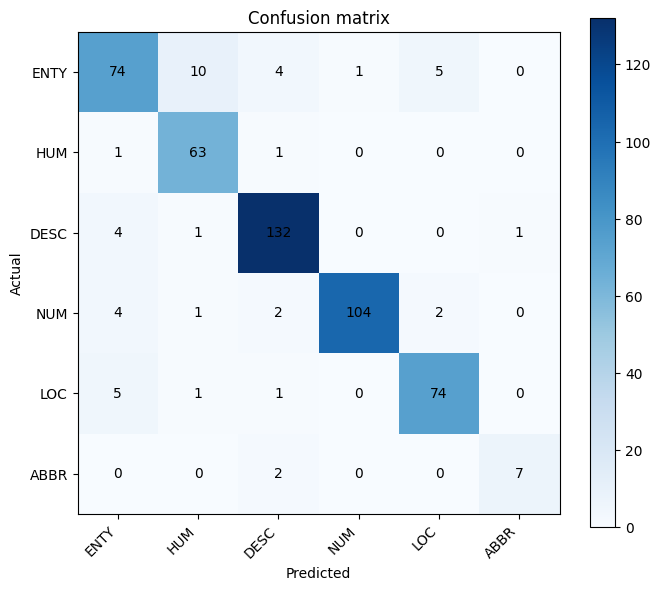

In [ ]:
# ------------------------------
# Part 2 (fixed): Model + Training using TorchText pipeline
# ------------------------------
import torch
import torch.nn as nn
import torch.optim as optim
from torchtext import data
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# ------------------------------
# Config (tweak as you like)
# ------------------------------
RNN_TYPE = 'LSTM'          # 'LSTM' | 'GRU' | 'RNN'
HIDDEN_DIM = 128
N_LAYERS = 1
DROPOUT = 0.5
BIDIRECTIONAL = True      # use bidirectional RNN
BATCH_SIZE = 64
N_EPOCHS = 15
LEARNING_RATE = 1e-3
GRAD_CLIP = 1.0
PATIENCE = 5              # early stopping patience

# ------------------------------
# Device
# ------------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


# Create a validation split from train_data
train_data, valid_data = train_data.split(split_ratio=0.85, random_state=random.seed(42))

# Build iterators for train / valid / test
train_loader, valid_loader, test_loader = data.BucketIterator.splits(
    (train_data, valid_data, test_data),
    batch_size=BATCH_SIZE,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text),
    device=device
)


# ------------------------------
# Build Embedding layer from TEXT.vocab
# If you earlier called TEXT.build_vocab(..., vectors='glove.6B.100d'),
# then TEXT.vocab.vectors will contain pretrained vectors.
# ------------------------------
vocab_size = len(TEXT.vocab)
print(f"Vocab size: {vocab_size}")

# If pretrained vectors exist, use them; otherwise init randomly
# if hasattr(TEXT.vocab, 'vectors') and TEXT.vocab.vectors is not None and TEXT.vocab.vectors.shape[0] > 0:
#     embedding_dim = TEXT.vocab.vectors.size(1)
#     embedding_layer = nn.Embedding.from_pretrained(TEXT.vocab.vectors, freeze=False, padding_idx=TEXT.vocab.stoi[TEXT.pad_token])
#     print(f"Using pretrained vectors. Embedding dim = {embedding_dim}")
# if using pretrained vectors, initialize unk vector to mean of pretrained vectors
if hasattr(TEXT.vocab, 'vectors') and TEXT.vocab.vectors is not None and TEXT.vocab.vectors.shape[0] > 0:
    vectors = TEXT.vocab.vectors  # Tensor [vocab_size, emb_dim]
    unk_idx = TEXT.vocab.stoi[TEXT.unk_token]
    pad_idx = TEXT.vocab.stoi[TEXT.pad_token]
    # compute mean excluding pad and unk if possible
    mask = torch.ones(vectors.size(0), dtype=torch.bool)
    mask[pad_idx] = False
    mask[unk_idx] = False
    mean_vec = vectors[mask].mean(dim=0)
    # Set unk vector to mean (this reduces harm of randomly init unk)
    vectors[unk_idx] = mean_vec
    # Optionally set pad to zeros
    vectors[pad_idx] = torch.zeros(vectors.size(1))
else:
    embedding_dim = 100
    embedding_layer = nn.Embedding(vocab_size, embedding_dim, padding_idx=TEXT.vocab.stoi[TEXT.pad_token])
    print(f"No pretrained vectors found. Random init embedding dim = {embedding_dim}")

output_size = len(LABEL.vocab)  # number of classes
print(f"Number of output classes: {output_size}")

# ------------------------------
# Model definition (embedding + RNN + FC)
# ------------------------------
class TorchTextRNN(nn.Module):
    def __init__(self, embedding_layer, embedding_dim, hidden_dim, output_dim,
                 n_layers=1, bidirectional=False, dropout=0.5, rnn_type='LSTM'):
        super().__init__()
        self.embedding = embedding_layer
        self.rnn_type = rnn_type
        self.bidirectional = bidirectional
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.num_directions = 2 if bidirectional else 1

        if rnn_type == 'LSTM':
            self.rnn = nn.LSTM(embedding_dim,
                               hidden_dim,
                               num_layers=n_layers,
                               batch_first=True,
                               bidirectional=bidirectional,
                               dropout=dropout if n_layers > 1 else 0)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(embedding_dim,
                              hidden_dim,
                              num_layers=n_layers,
                              batch_first=True,
                              bidirectional=bidirectional,
                              dropout=dropout if n_layers > 1 else 0)
        else:
            self.rnn = nn.RNN(embedding_dim,
                              hidden_dim,
                              num_layers=n_layers,
                              batch_first=True,
                              bidirectional=bidirectional,
                              nonlinearity='tanh',
                              dropout=dropout if n_layers > 1 else 0)

        # Final linear uses hidden_dim * num_directions
        self.fc = nn.Linear(hidden_dim * self.num_directions, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text, text_lengths):
        # text: [seq_len, batch] if torchtext default, but BucketIterator gives [batch, seq_len] when batch_first=False
        # Your TEXT Field likely yields shape [seq_len, batch] — check: many examples use transpose below
        # We designed train/test loaders with device and sort_within_batch=True; bucket iterator yields (text, text_lengths)
        # In torchtext 0.4, batch.text is [seq_len, batch]; with include_lengths=True, you receive (text, lengths)
        # We will support both shapes:
        if isinstance(text, tuple) or isinstance(text, list):
            text, text_lengths = text  # sometimes text already packaged
        # text expected shape: [seq_len, batch] (common in older torchtext) -> convert to [batch, seq_len]
        if text.dim() == 2 and text.size(0) != text_lengths.size(0):
            # heuristic: if first dim is seq_len, transpose
            text = text.transpose(0, 1)

        # text: [batch, seq_len]
        embedded = self.embedding(text)            # [batch, seq_len, emb_dim]
        embedded = self.dropout(embedded)

        # pack padded sequence (requires lengths on CPU and in descending order - BucketIterator handles sorting)
        # text_lengths: tensor [batch]
        packed = nn.utils.rnn.pack_padded_sequence(embedded, text_lengths.cpu(), batch_first=True, enforce_sorted=True)

        # rnn
        packed_out, hidden = self.rnn(packed)   # packed_out is PackedSequence
        # hidden: for LSTM -> (h_n, c_n), for GRU/RNN -> h_n

        if self.rnn_type == 'LSTM':
            h_n = hidden[0]   # [num_layers * num_directions, batch, hidden_dim]
        else:
            h_n = hidden     # GRU or RNN: [num_layers * num_directions, batch, hidden_dim]

        # get last layer's hidden state
        # reshape and concat directions if bidirectional
        # select the last layer:
        last_layer_index = (self.n_layers - 1) * self.num_directions
        if self.bidirectional:
            # take forward and backward for the last layer and concat
            forward_h = h_n[last_layer_index, :, :]               # [batch, hidden_dim]
            backward_h = h_n[last_layer_index + 1, :, :]          # [batch, hidden_dim]
            h_final = torch.cat((forward_h, backward_h), dim=1)  # [batch, hidden_dim * 2]
        else:
            h_final = h_n[last_layer_index, :, :]                # [batch, hidden_dim]

        h_final = self.dropout(h_final)
        logits = self.fc(h_final)    # [batch, output_dim]
        return logits

# Instantiate model
model = TorchTextRNN(
    embedding_layer=embedding_layer,
    embedding_dim=embedding_dim,
    hidden_dim=HIDDEN_DIM,
    output_dim=output_size,
    n_layers=N_LAYERS,
    bidirectional=BIDIRECTIONAL,
    dropout=DROPOUT,
    rnn_type=RNN_TYPE
).to(device)

print(f'Model parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

# ------------------------------
# Loss & Optimizer
# ------------------------------
criterion = nn.CrossEntropyLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# ------------------------------
# Utility: accuracy
# ------------------------------
def categorical_accuracy(preds, y):
    """
    preds: [batch, n_classes], y: [batch]
    """
    top_pred = preds.argmax(1, keepdim=False)
    correct = top_pred.eq(y).sum().item()
    return correct / y.size(0)

# ------------------------------
# Train & Eval functions (compatible with torchtext batches)
# ------------------------------
def train_epoch(model, iterator, optimizer, criterion, device):
    epoch_loss = 0.0
    epoch_acc = 0.0
    model.train()
    for batch in iterator:
        # With torchtext Field(include_lengths=True), batch.text is a tuple (text, text_lengths)
        text, text_lengths = batch.text
        # If text shape is [seq_len, batch], note we handle transpose in forward
        labels = batch.label.long().to(device)            # ensure long
        optimizer.zero_grad()
        predictions = model(text.to(device), text_lengths.to(device))
        loss = criterion(predictions, labels)
        acc = categorical_accuracy(predictions, labels)
        loss.backward()
        if GRAD_CLIP is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        epoch_loss += loss.item()
        epoch_acc += acc
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion, device):
    epoch_loss = 0.0
    epoch_acc = 0.0
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch in iterator:
            text, text_lengths = batch.text
            labels = batch.label.long().to(device)
            predictions = model(text.to(device), text_lengths.to(device))
            loss = criterion(predictions, labels)
            acc = categorical_accuracy(predictions, labels)
            epoch_loss += loss.item()
            epoch_acc += acc
            all_preds.extend(predictions.argmax(1).cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())
    return epoch_loss / len(iterator), epoch_acc / len(iterator), all_preds, all_labels

# ------------------------------
# Training loop with early stopping
# ------------------------------
best_valid_acc = 0.0
patience_counter = 0

train_losses, valid_losses = [], []
train_accs, valid_accs = [], []

print("Starting training...")
for epoch in range(N_EPOCHS):
    # inside training loop
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    valid_loss, valid_acc, _, _ = evaluate(model, valid_loader, criterion, device)  # validate on valid_loader


    train_losses.append(train_loss); valid_losses.append(valid_loss)
    train_accs.append(train_acc); valid_accs.append(valid_acc)

    print(f"Epoch {epoch+1}/{N_EPOCHS} — train loss: {train_loss:.4f} | train acc: {train_acc*100:.2f}%"
          f" — val loss: {valid_loss:.4f} | val acc: {valid_acc*100:.2f}%")

    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(model.state_dict(), 'best_trec_rnn.pt')
        patience_counter = 0
        print("  Best model saved.")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping (no improvement in {PATIENCE} epochs).")
            break

# Load best model
model.load_state_dict(torch.load('best_trec_rnn.pt'))
print("Best model loaded for final evaluation.")

# ------------------------------
# Final evaluation & reports
# ------------------------------

test_loss, test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion, device)
print(f"Final Test — loss: {test_loss:.4f} | acc: {test_acc*100:.2f}%")

# Convert numeric labels back to strings
label_names = LABEL.vocab.itos  # torchtext LabelField vocab contains list of label strings
print("\nClassification report:")
print(classification_report(test_labels, test_preds, target_names=label_names))

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion matrix')
plt.colorbar()
plt.xticks(range(len(label_names)), label_names, rotation=45, ha='right')
plt.yticks(range(len(label_names)), label_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center', color='black')
plt.tight_layout()
plt.show()
